In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind

Difference-in-Differences (DiD) — оцінка ефекту без повної рандомізації

- Використовується, коли treatment увімкнули для однієї групи, а інша лишилась контролем, і є дані **до** і **після**.
- DiD = `(mean_post_target − mean_pre_target) − (mean_post_control − mean_pre_control)`  
  тобто різниця змін депозиту між групами.
- Ключове припущення — **parallel trends**: без treatment обидві групи рухались би паралельно.
- DiD прибирає стабільні в часі відмінності між групами через різницю «до/після».

In [2]:
def difference_in_differences(
    df,
    target_col='target',
    value_col='gross_summ',
    pre_col='gross_summ_pre',
    alternative='two-sided',
    confidence_level=0.95
):
    """
    Оцінює ефект treatment через Difference-in-Differences.

    Очікує wide-формат (як CUPED): один рядок на юзера з метрикою
    до спліту (pre) і після (value). DiD = різниця середніх змін
    (value − pre) між target і control.

    Параметри
    ---------
    df : pandas.DataFrame
        Датафрейм з групою, метрикою після спліту та до спліту.

    target_col : str, за замовчуванням 'target'
        1 — група з treatment, 0 — control.

    value_col : str, за замовчуванням 'gross_summ'
        Метрика після спліту / під час експерименту.

    pre_col : str, за замовчуванням 'gross_summ_pre'
        Та сама метрика до спліту.

    alternative : {'two-sided', 'greater', 'less'}, за замовчуванням 'two-sided'
        Тип t-тесту для різниці змін (target − control).

    confidence_level : float, за замовчуванням 0.95
        Рівень довіри для CI.

    Повертає
    --------
    pandas.DataFrame
        Один рядок:
        - Metric / Pre Metric
        - DiD : різниця змін (target − control)
        - Mean Delta Target / Mean Delta Control
        - Mean Target Pre/Post, Mean Control Pre/Post
        - CI Lower / CI Upper, T-test p-value
        - N Target / N Control

    Приклади
    --------
    >>> difference_in_differences(df, value_col='gross_summ', pre_col='gross_summ_pre')
    """
    data = df[[target_col, value_col, pre_col]].dropna().copy()
    data['_delta'] = data[value_col].astype(float) - data[pre_col].astype(float)

    tr = data.loc[data[target_col] == 1]
    co = data.loc[data[target_col] == 0]

    ttest = ttest_ind(
        tr['_delta'], co['_delta'],
        equal_var=False,
        alternative=alternative
    )
    ci = ttest.confidence_interval(confidence_level=confidence_level)

    return pd.DataFrame([{
        'Metric': value_col,
        'Pre Metric': pre_col,
        'DiD': round(tr['_delta'].mean() - co['_delta'].mean(), 4),
        'Mean Delta Target': round(tr['_delta'].mean(), 4),
        'Mean Delta Control': round(co['_delta'].mean(), 4),
        'Mean Target Pre': round(tr[pre_col].mean(), 4),
        'Mean Target Post': round(tr[value_col].mean(), 4),
        'Mean Control Pre': round(co[pre_col].mean(), 4),
        'Mean Control Post': round(co[value_col].mean(), 4),
        'CI Lower': round(ci.low, 4),
        'CI Upper': round(ci.high, 4),
        'T-test p-value': round(ttest.pvalue, 4),
        'N Target': len(tr),
        'N Control': len(co),
    }])

In [3]:
def plot_did(
    df,
    target_col='target',
    value_col='gross_summ',
    pre_col='gross_summ_pre'
):
    """
    Візуалізація DiD: середні pre → post для target і control.

    Параметри
    ---------
    df : pandas.DataFrame
        Wide-формат з target, value_col, pre_col.

    target_col / value_col / pre_col : str
        Назви стовпців групи, post-метрики та pre-метрики.
    """
    data = df[[target_col, value_col, pre_col]].dropna().copy()

    rows = []
    for group_val, label in [(0, 'control'), (1, 'target')]:
        part = data.loc[data[target_col] == group_val]
        rows.append({'group': label, 'period': 'pre', 'mean': part[pre_col].mean()})
        rows.append({'group': label, 'period': 'post', 'mean': part[value_col].mean()})
    means = pd.DataFrame(rows)

    did = (
        means.query("group == 'target' and period == 'post'")['mean'].iloc[0]
        - means.query("group == 'target' and period == 'pre'")['mean'].iloc[0]
        - (
            means.query("group == 'control' and period == 'post'")['mean'].iloc[0]
            - means.query("group == 'control' and period == 'pre'")['mean'].iloc[0]
        )
    )

    fig, ax = plt.subplots(figsize=(7, 4))
    period_map = {'pre': 0, 'post': 1}

    for label, color, marker in [
        ('control', 'steelblue', 'o'),
        ('target', 'darkorange', 's'),
    ]:
        part = means[means['group'] == label].copy()
        part['x'] = part['period'].map(period_map)
        part = part.sort_values('x')
        ax.plot(part['x'], part['mean'], marker=marker, color=color, linewidth=2, label=label)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['pre', 'post'])
    ax.set_ylabel(value_col)
    ax.set_title(f'DiD: {did:.3f}')
    ax.legend(title='Група')
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### демо

Симулюємо юзерів у тому ж форматі, що CUPED: `gross_summ_pre` до спліту, `gross_summ` після; у target після запуску з’являється uplift.

In [4]:
rng = np.random.default_rng(7)
n = 2000

target = rng.integers(0, 2, size=n)
gross_summ_pre = rng.normal(100, 10, size=n) + 5.0 * target
true_effect = 8.0
time_trend = 3.0

gross_summ = (
    gross_summ_pre
    + time_trend
    + true_effect * target
    + rng.normal(0, 4, size=n)
)

df = pd.DataFrame({
    'user_id': np.arange(n),
    'target': target,
    'gross_summ': gross_summ,
    'gross_summ_pre': gross_summ_pre,
})

df.head()

,user_id,target,gross_summ,gross_summ_pre
0,0,1,91.166304,89.327056
1,1,1,109.322256,104.732922
2,2,1,122.055405,109.968235
3,3,1,126.037971,115.230260
4,4,1,113.586085,103.582721


In [5]:
difference_in_differences(
    df,
    target_col='target',
    value_col='gross_summ',
    pre_col='gross_summ_pre'
)

,Metric,Pre Metric,DiD,Mean Delta Target,Mean Delta Control,Mean Target Pre,Mean Target Post,Mean Control Pre,Mean Control Post,CI Lower,CI Upper,T-test p-value,N Target,N Control
0,gross_summ,gross_summ_pre,8.1523,11.0489,2.8966,105.2878,116.3366,99.6116,102.5082,7.8017,8.5028,0.0,1010,990


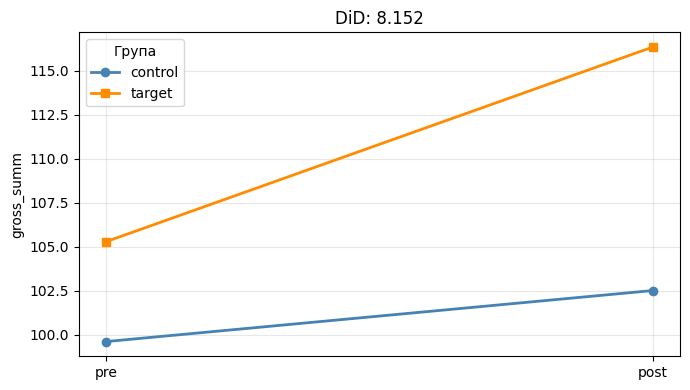

In [6]:
plot_did(
    df,
    target_col='target',
    value_col='gross_summ',
    pre_col='gross_summ_pre'
)